In [1]:
import joblib
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
from pathlib import Path

from sklearn.metrics import pairwise_distances
from scipy.interpolate import PchipInterpolator as Pchip


# Load and paths

In [2]:
#load pipelines
cwd = Path.cwd()
pipe_base_path = cwd.parent.parent/"pipelines_others"/"gp_tunning_opt5_v15_pipeline.pkl"
pipe_opt_path  = cwd.parent.parent/"pipelines_others"/"gp_pipeline_latest_opt5_v15.pkl"
pipeline_base = joblib.load(pipe_base_path)
pipeline_upd = joblib.load(pipe_opt_path)



In [3]:
# load data and references

version='v15'
sampling_data_path=Path(f'{cwd.parent.parent}/results_{version}/morris_samples_{version}.csv').resolve()
results_path=Path(f"{cwd.parent.parent}/results_{version}/results/raw_data").resolve()
field_data_path=Path(f"{cwd.parent.parent}/STIMTEC_example/BH10_20180718_40.6_SR_v2.csv")

raw_paths= list((results_path).glob("*.npy"))

file_paths= sorted(
    raw_paths,
    key= lambda p: int(p.stem.split("_")[2])
)

iter_list=[np.load(file,allow_pickle=True).item() for file in file_paths]

sampling_data=pd.read_csv(sampling_data_path,header=0)
field_data=pd.read_csv(field_data_path,header=0)


target_y_opt = pd.read_csv(f"{cwd.parent.parent}/pipelines_others/base_target_y_opt5_v15.csv", header=0)

runname='conf-L-sf0'
runfile='v15_opt5'
opt_path_dir=Path(f"{cwd.parent.parent}/run_{runname}/opt_val_bh10_40_6_run_{runfile}.csv").resolve()
opt_path_data=pd.read_csv(opt_path_dir,header=0)

# functions

In [ ]:
def normalise_parity(original: pd.DataFrame | pd.Series | np.array,
                     predict: pd.DataFrame | pd.Series | np.array
                   ) -> None:
    """applies re-scalin value-min/range to two variables"""
    
    normalise = (predict - np.min(original)) / (np.max(original) - np.min(original))
    return normalise

# processing

In [4]:
sampling_data["log_sf0"] = np.log(sampling_data["sf0"])
opt_path_data["log_sf0"] = np.log(opt_path_data["sf0"])

x_base =sampling_data[list(pipeline_base.feature_names_in_)].copy()
x_base_scaled = pipeline_base["scaler"].transform(x_base)

x_new =opt_path_data[list(pipeline_base.feature_names_in_)].copy()
x_new_scaled = pipeline_base["scaler"].transform(x_new)



In [5]:
dist_matrix = pairwise_distances(x_new_scaled, x_base_scaled, metric = "euclidean")
min_distances = np.min(dist_matrix, axis= 1)

# p_mean_base, p_std_base = pipeline_base["gp"].predict(x_new_scaled, return_std = True)
# p_mean_new, p_std_new = pipeline_upd["gp"].predict(x_new_scaled, return_std = True)

p_mean_base, p_std_base = pipeline_base.predict(x_new, return_std = True)
p_mean_new, p_std_new = pipeline_upd.predict(x_new, return_std = True)

p_mean_base = p_mean_base.ravel()
p_mean_new = p_mean_new.ravel()

c:\Miniforge-Data\envs\Data_Analysis\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but MinMaxScaler was fitted without feature names
  warnings.warn(


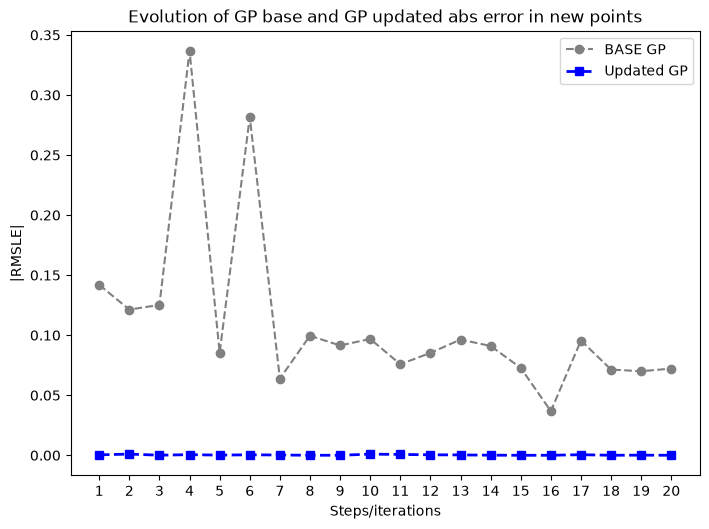

In [7]:
base_cost = opt_path_data["cost"]
error_base = abs(base_cost - p_mean_base)
error_updated = abs(base_cost - p_mean_new)

steps = np.arange(1, len(base_cost) +1)

plt.figure(figsize=(7,5))


plt.plot(
    steps,
    error_base,
    "o--",
    color = "gray",
    lw= 1.5,
    label= "BASE GP"
)


plt.plot(
    steps,
    error_updated,
    "s--",
    color = "blue",
    lw= 2.0,
    label= "Updated GP"
)


plt.xticks(steps)
plt.legend()
plt.tight_layout()

plt.title("Evolution of GP base and GP updated abs error in new points")
plt.ylabel("|RMSLE|")
plt.xlabel("Steps/iterations")

plt.show()

In [8]:
#predict and see p_ againts #set

p_mean_1, p_std_1 = pipeline_base.predict(x_base, return_std = True)
p_mean_1 = p_mean_1.ravel()

xvalues = np.linspace(0,150,150)
# p_mean_range = p_mean_1.max()-p_mean_1.min()
# p_mean_1 = normalise_parity(p_mean_1, p_mean_1)
# p_std_1 = p_std_1/p_mean_range

up = p_mean_1 + 1.96*p_std_1
down = p_mean_1 - 1.96*p_std_1



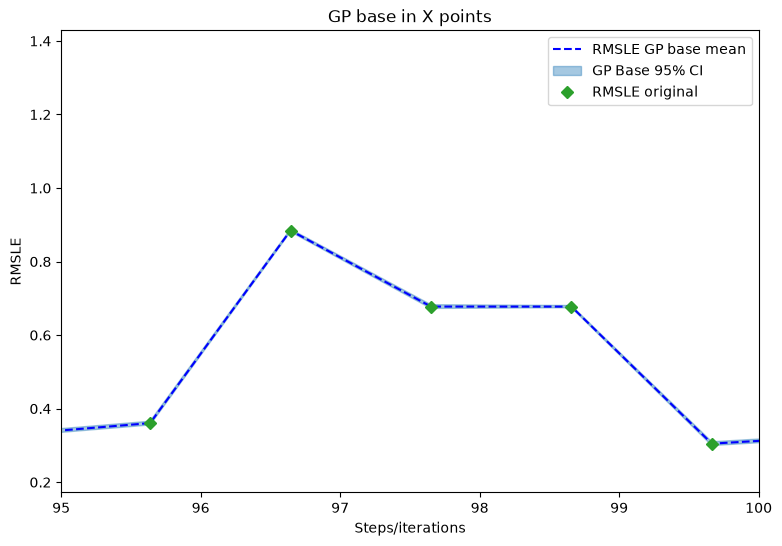

In [9]:
fig0, axs = plt.subplots( figsize=(9,6))

axs.plot(
    xvalues,
    p_mean_1,
    "b--",
    label = "RMSLE GP base mean"
)

axs.fill_between(
    xvalues,
    up,
    down,
    color = "tab:blue",
    interpolate= True, 
    alpha = 0.4,
    label = "GP Base 95% CI"
)

axs.plot(
    xvalues,
    target_y_opt,
    ls = "",
    marker= "D",
    color = "tab:green",
    label = "RMSLE original"
)

axs.set_xlim(95,100)
axs.set_ylabel("RMSLE")
axs.set_xlabel("Steps/iterations")


plt.title("GP base in X points")
plt.legend()

plt.show()